### Import Library & Read Dataset

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

df_raw = pd.read_csv('../dataset/jakarta_house.csv')
print(f"Dataset awal berhasil dimuat! Ukuran data: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
display(df_raw.head())


Dataset awal berhasil dimuat! Ukuran data: 10000 baris, 9 kolom


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### Memilih Fitur

In [12]:
kolom_digunakan = [
    'price', 'district', 'city', 'bed_rooms', 
    'bath_rooms', 'carport', 'land_area', 'building_area'
]
df_filtered = df_raw[kolom_digunakan].copy()

print("Hasil Column Filter:")
display(df_filtered.head())

Hasil Column Filter:


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### Pengecekan & Pembersihan Missing Value

In [13]:
print("Jumlah missing value sebelum dibersihkan:")
print(df_filtered.isnull().sum())

df_cleaned = df_filtered.dropna().reset_index(drop=True)
print(f"\nUkuran data setelah pembersihan missing value: {df_cleaned.shape[0]} baris, {df_cleaned.shape[1]} kolom")

Jumlah missing value sebelum dibersihkan:
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        3
building_area    5
dtype: int64

Ukuran data setelah pembersihan missing value: 9992 baris, 8 kolom


### Pengecekan & Pembersihan Data Duplikat

In [14]:
print("Jumlah data duplikat :", df_cleaned.duplicated().sum())
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
print(f"Ukuran data setelah hapus duplikat      : {df_cleaned.shape[0]} baris")
print("Jumlah data duplikat :", df_cleaned.duplicated().sum())

Jumlah data duplikat : 526
Ukuran data setelah hapus duplikat      : 9466 baris
Jumlah data duplikat : 0


### Encoding district & city

In [15]:
df_encoded = df_cleaned.copy()
le_district = LabelEncoder()
le_city = LabelEncoder()

df_encoded['district'] = le_district.fit_transform(df_encoded['district'])
df_encoded['city'] = le_city.fit_transform(df_encoded['city'])

print("Hasil Encoding:")
display(df_encoded.head())

Hasil Encoding:


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,39,0,2,4,2,250.0,350.0
1,2700000000,74,0,4,2,0,100.0,225.0
2,2200000000,74,0,3,3,0,60.0,140.0
3,1900000000,74,0,3,2,0,60.0,120.0
4,2100000000,234,0,4,3,0,56.0,108.0


### Deteksi & Penanganan Outlier

In [16]:
# Penanganan Outlier menggunakan metode Interquartile Range (IQR 1,5)
Q1 = df_encoded.quantile(0.25)
Q3 = df_encoded.quantile(0.75)
IQR = Q3 - Q1

# Menentukan Batas Bawah dan Batas Atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas  = Q3 + 1.5 * IQR

# Mendeteksi data yang berada di bawah Batas Bawah atau di atas Batas Atas
kondisi_outlier = (df_encoded < batas_bawah) | (df_encoded > batas_atas)

# Menampilkan Tabel Analisis Jumlah Outlier Sebelum Ditangani
tabel_sebelum = pd.DataFrame({
    'Jumlah Data': len(df_encoded),
    'Jumlah Outlier': kondisi_outlier.sum(),
    'Batas Bawah': batas_bawah.round(2),
    'Batas Atas': batas_atas.round(2)
})
print("TABEL ANALISIS JUMLAH OUTLIER SEBELUM DITANGANI: ")
display(tabel_sebelum)

# Menghapus baris yang memiliki nilai di luar Batas Bawah dan Batas Atas
df_bersih_outlier = df_encoded[~kondisi_outlier.any(axis=1)].reset_index(drop=True)

kondisi_outlier_setelah = (df_bersih_outlier < batas_bawah) | (df_bersih_outlier > batas_atas)

# Menampilkan Tabel Hasil Setelah Penanganan Outlier
tabel_sesudah = pd.DataFrame({
    'Jumlah Data': len(df_bersih_outlier),
    'Jumlah Outlier': kondisi_outlier_setelah.sum(),
    'Batas Bawah': batas_bawah.round(2),
    'Batas Atas': batas_atas.round(2)
})
print("\nTABEL HASIL SETELAH PENANGANAN OUTLIER: ")
display(tabel_sesudah)

print(f"\nTotal data sebelum penanganan outlier : {len(df_encoded)} baris")
print(f"Total data setelah penanganan outlier : {len(df_bersih_outlier)} baris")

TABEL ANALISIS JUMLAH OUTLIER SEBELUM DITANGANI: 


,Jumlah Data,Jumlah Outlier,Batas Bawah,Batas Atas
price,9466,1023,-8.600000e+09,2.100000e+10
district,9466,0,-1.160000e+02,3.480000e+02
city,9466,0,-4.500000e+00,7.500000e+00
bed_rooms,9466,290,0.000000e+00,8.000000e+00
bath_rooms,9466,255,-1.000000e+00,7.000000e+00
carport,9466,764,-5.000000e-01,3.500000e+00
land_area,9466,821,-2.561200e+02,6.988800e+02
building_area,9466,633,-2.500000e+02,7.900000e+02



TABEL HASIL SETELAH PENANGANAN OUTLIER: 


,Jumlah Data,Jumlah Outlier,Batas Bawah,Batas Atas
price,7567,0,-8.600000e+09,2.100000e+10
district,7567,0,-1.160000e+02,3.480000e+02
city,7567,0,-4.500000e+00,7.500000e+00
bed_rooms,7567,0,0.000000e+00,8.000000e+00
bath_rooms,7567,0,-1.000000e+00,7.000000e+00
carport,7567,0,-5.000000e-01,3.500000e+00
land_area,7567,0,-2.561200e+02,6.988800e+02
building_area,7567,0,-2.500000e+02,7.900000e+02



Total data sebelum penanganan outlier : 9466 baris
Total data setelah penanganan outlier : 7567 baris


### Visualisasi Boxplot Setelah Penghapusan Outlier

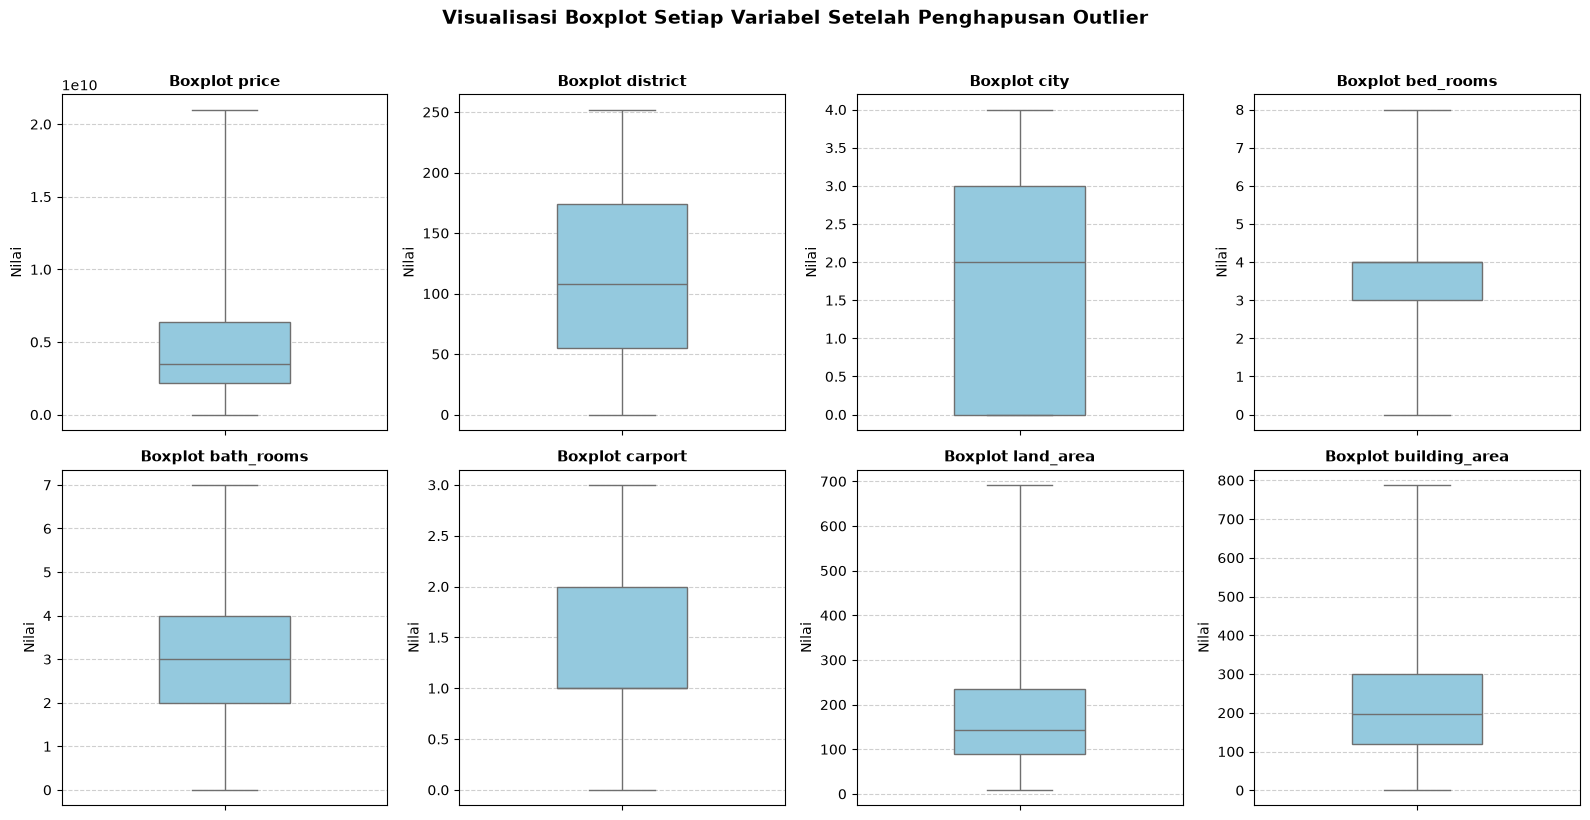

In [17]:
# Menampilkan Boxplot untuk seluruh 8 atribut setelah penghapusan outlier
kolom_fitur = df_bersih_outlier.columns

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_fitur):
    sns.boxplot(y=df_bersih_outlier[col], ax=axes[i], color='skyblue', width=0.4, whis=(0, 100))
    axes[i].set_title(f'Boxplot {col}', fontweight='bold', fontsize=11)
    axes[i].set_ylabel('Nilai')
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

plt.suptitle('Visualisasi Boxplot Setiap Variabel Setelah Penghapusan Outlier', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Normalisasi Teknik Gaussian (Z-Score)

In [18]:
scaler = StandardScaler()

df_normalized = pd.DataFrame(
    scaler.fit_transform(df_bersih_outlier),
    columns=df_bersih_outlier.columns
)

print("Hasil Normalisasi:")
display(df_normalized.head().round(3))

Hasil Normalisasi:


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,0.269,-1.108,-1.295,-1.341,0.828,0.970,0.563,0.901
1,-0.550,-0.617,-1.295,0.233,-0.883,-1.397,-0.649,-0.002
2,-0.678,-0.617,-1.295,-0.554,-0.027,-1.397,-0.972,-0.615
3,-0.755,-0.617,-1.295,-0.554,-0.883,-1.397,-0.972,-0.760
4,-0.704,1.630,-1.295,0.233,-0.027,-1.397,-1.005,-0.846


### Partitioning Data (80% Training : 20% Testing)

In [19]:
X = df_normalized.drop(columns=['price'])
y = df_normalized['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

print(f"Jumlah Data Training (80%): {len(X_train)} data")
print(f"Jumlah Data Testing  (20%): {len(X_test)} data")

Jumlah Data Training (80%): 6053 data
Jumlah Data Testing  (20%): 1514 data


### Menyimpan Data Hasil Preprocessing

In [20]:
joblib.dump((X_train, X_test, y_train, y_test, scaler), '../dataset/data_hasil_preprocessing.pkl')
print("Data siap pemodelan berhasil disimpan ke '../dataset/data_hasil_preprocessing.pkl'!")

Data siap pemodelan berhasil disimpan ke '../dataset/data_hasil_preprocessing.pkl'!
